# Fictitious Play and Regret in Matrix Games

Portfolio packaging for Behrad Mazaheri. Original course/template credits below are retained; individual contributions are unverified.

**Static review only; no cells executed.** Historical outputs are preserved, not independently reproduced. Read README and REVIEW before citing results. Source cell indices in documentation are zero-based before this banner.

NumPy matrix-game experiments, not deep multi-agent RL. Empirical action frequencies and regret diagnostics do not prove general convergence of fictitious play or identify a pure equilibrium.


# **Multi-Agent Reinforcement Learning**



---
## Nash Equilibrium (Theory)

A Nash Equilibrium (NE) represents a state where no player can improve their outcome by unilaterally changing their strategy. For our games, we'll focus on finding the mixed-strategy NE, where players choose their actions probabilistically.

### 1.1 Standard Medieval Warfare (Cavalry-Infantry-Archers)

In this tactical game, two generals face off. Cavalry beats Archers, Archers beat Infantry, and Infantry beats Cavalry. Given the standard payoff matrix:

| Player 1 | Cavalry | Infantry | Archers |
| :--- | :--: | :---: | :---: |
| **Cavalry** | 0, 0 | -1, 1 | 1, -1 |
| **Infantry**| 1, -1 | 0, 0 | -1, 1 |
| **Archers** | -1, 1 | 1, -1 | 0, 0 |

**Your Task:** Analytically derive the mixed-strategy Nash Equilibrium for this game. Show the steps for setting up the indifference equations for Player 1 and solving for Player 2's equilibrium strategy probabilities $(q_C, q_I, q_A)$. (Find the Mixed Nash equilibrium of the game).

### 1.2 Modified Medieval Warfare

Now, consider a modified game where the terrain alters the combat effectiveness. A Cavalry charge against Archers is absolutely devastating, but Archers have a stronger high-ground advantage against Infantry:

| Player 1 | Cavalry | Infantry | Archers |
| :--- | :--: | :---: | :---: |
| **Cavalry** | 0, 0 | -1, 1 | 3, -3 |
| **Infantry**| 1, -1 | 0, 0 | -2, 2 |
| **Archers** | -3, 3 | 2, -2 | 0, 0 |

**Your Task:** Like the previous one, derive the mixed-strategy Nash Equilibrium for this modified game. Show your work as you calculate the new probability distribution.

## Answer to Problem 1

### 1.1 Standard game

Let Player 2 use $q=(q_C,q_I,q_A)$. Player 1's expected payoff from each pure action is

$$
U_C=-q_I+q_A,\qquad
U_I=q_C-q_A,\qquad
U_A=-q_C+q_I.
$$

At a completely mixed Nash equilibrium Player 1 must be indifferent, so

$$
-q_I+q_A=q_C-q_A=-q_C+q_I,
\qquad q_C+q_I+q_A=1.
$$

Solving gives

$$q_C=q_I=q_A=\frac13.$$

The game is symmetric and zero-sum, hence Player 1 has the same equilibrium distribution. Therefore

$$
p^*=q^*=\left(\frac13,\frac13,\frac13\right),\qquad v=0.
$$

### 1.2 Modified game

For the modified payoff matrix, Player 1's pure-action payoffs against $q$ are

$$
U_C=-q_I+3q_A,\qquad
U_I=q_C-2q_A,\qquad
U_A=-3q_C+2q_I.
$$

The matrix is again skew-symmetric, so the zero-sum game has value $v=0$. Indifference therefore gives

$$
-q_I+3q_A=0,\qquad q_C-2q_A=0,
\qquad -3q_C+2q_I=0.
$$

Thus $q_I=3q_A$ and $q_C=2q_A$. Using $q_C+q_I+q_A=1$ gives $6q_A=1$, so

$$
q^*=\left(q_C,q_I,q_A\right)
=\left(\frac13,\frac12,\frac16\right).
$$

By symmetry, Player 1 uses the same distribution:

$$
p^*=q^*=\left(\frac13,\frac12,\frac16\right),\qquad v=0.
$$

## Problem 2: Learning by Observation - Fictitious Play (Implementation)

Fictitious Play is an intuitive learning algorithm where each agent models its opponent as playing a stationary strategy defined by the historical frequency of their past actions. The agent then plays a **best response** to this belief.

### 2.1 Implementation

**Your Task:** Implement the `simulate_fictitious_play` function below. It should take the payoff matrices for both players and the number of iterations as input. At each step, each player should choose the action that maximizes their expected payoff given the history of the opponent's plays.

**Algorithm:** At each time step $t > 0$, Player $i$ forms a belief that their opponent ($-i$) will play each action $a'$ with a probability equal to its historical frequency. The agent then chooses an action $a_i^*$ that is a best response to this belief.

Let $C_{t-1}(a_{-i})$ be the count of times opponent $-i$ has played action $a_{-i}$ up to step $t-1$. Player $i$'s best response is:
$$a_{i,t}^* = \arg\max_{a_i \in A_i} \sum_{a_{-i} \in A_{-i}} u_i(a_i, a_{-i}) \cdot \frac{C_{t-1}(a_{-i})}{t-1}$$

**Note on Tie-Breaking:** If multiple actions yield the same maximal expected payoff, your agent should choose one of these best responses uniformly at random.

**Your Task:**
1.  Run your simulation for **1,000,000 iterations** on both the **standard** and **modified** RSP games.
2.  Generate two plots, one for each game. Each plot should show the evolution of Players action frequencies over time and include horizontal lines indicating the theoretical NE probabilities you calculated in Problem 1.
3.  **Analyze your results:** Do the action frequencies converge? If so, do they converge to the Nash Equilibrium? Explain the observed behavior.

Running Standard Fictitious Play...
Running Modified Fictitious Play...


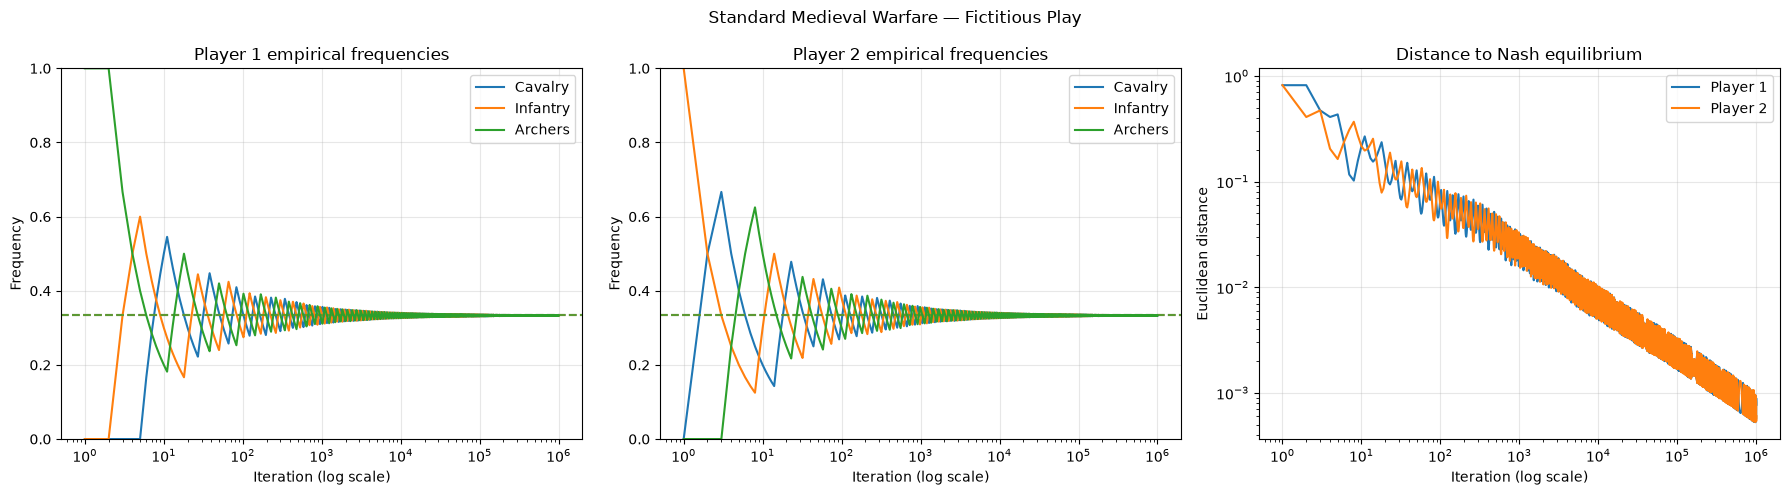

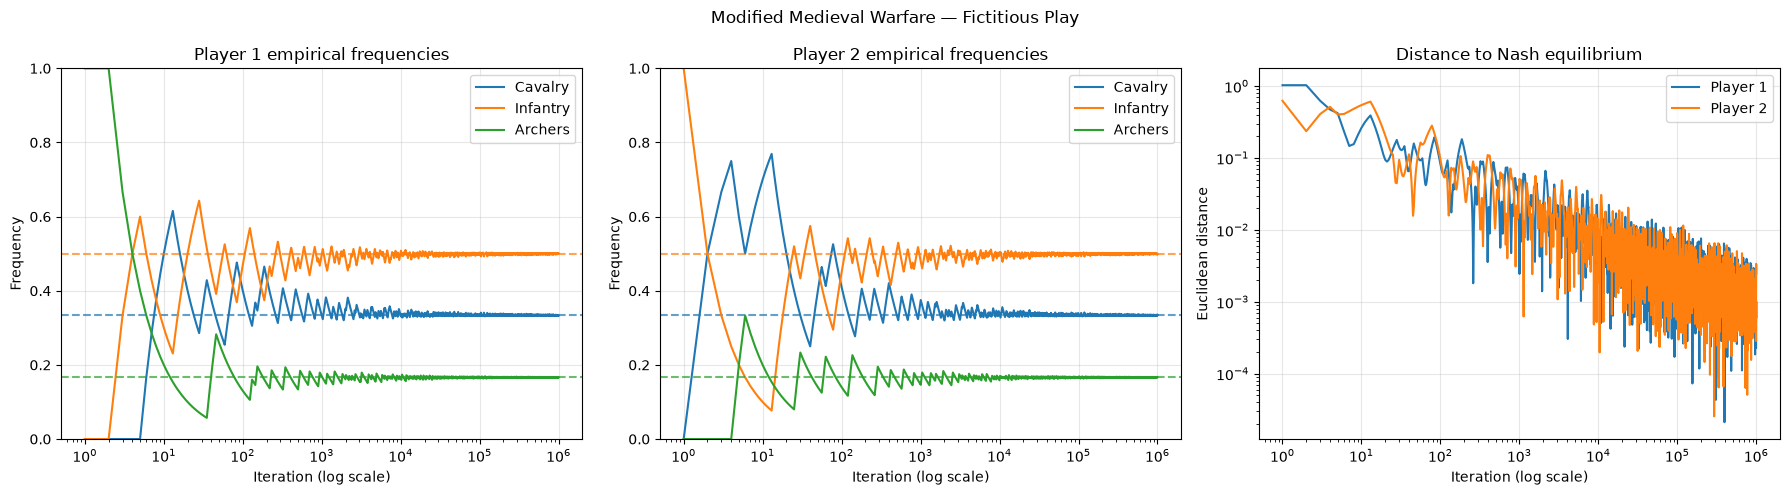

Standard final P1 frequencies: [0.333932 0.333204 0.332864]
Standard final P2 frequencies: [0.332842 0.333589 0.333569]
Standard final distances to NE: P1=0.000772, P2=0.000602
Modified final P1 frequencies: [0.333333 0.500432 0.166235]
Modified final P2 frequencies: [0.334977 0.498168 0.166855]
Modified final distances to NE: P1=0.000611, P2=0.002468


In [1]:
import numpy as np
import matplotlib.pyplot as plt


def random_argmax(values, rng):
    """Choose uniformly among all numerically tied maximizers."""
    values = np.asarray(values)
    candidates = np.flatnonzero(np.isclose(values, values.max(), rtol=1e-12, atol=1e-12))
    return int(rng.choice(candidates))


def simulate_fictitious_play(payoff_A, payoff_B, iterations, seed=0):
    """Simulate simultaneous two-player fictitious play."""
    payoff_A = np.asarray(payoff_A, dtype=np.float64)
    payoff_B = np.asarray(payoff_B, dtype=np.float64)
    if payoff_A.shape != payoff_B.shape or payoff_A.ndim != 2:
        raise ValueError("payoff_A and payoff_B must be two-dimensional matrices of equal shape")
    if iterations < 1:
        raise ValueError("iterations must be positive")

    num_actions_p1, num_actions_p2 = payoff_A.shape
    rng = np.random.default_rng(seed)
    p1_counts = np.zeros(num_actions_p1, dtype=np.int64)
    p2_counts = np.zeros(num_actions_p2, dtype=np.int64)
    p1_freq_history = np.empty((iterations, num_actions_p1), dtype=np.float32)
    p2_freq_history = np.empty((iterations, num_actions_p2), dtype=np.float32)

    # The first observation supplies a nonempty history for both beliefs.
    p1_action = int(rng.integers(num_actions_p1))
    p2_action = int(rng.integers(num_actions_p2))

    for t in range(iterations):
        p1_counts[p1_action] += 1
        p2_counts[p2_action] += 1

        p1_freq = p1_counts / (t + 1)
        p2_freq = p2_counts / (t + 1)
        p1_freq_history[t] = p1_freq
        p2_freq_history[t] = p2_freq

        # Both best responses are computed from the same pre-action history.
        p1_expected_payoffs = payoff_A @ p2_freq
        p2_expected_payoffs = p1_freq @ payoff_B
        p1_action = random_argmax(p1_expected_payoffs, rng)
        p2_action = random_argmax(p2_expected_payoffs, rng)

    return p1_freq_history, p2_freq_history


A_std = np.array([
    [0, -1, 1],
    [1, 0, -1],
    [-1, 1, 0],
], dtype=np.float64)
B_std = -A_std

A_mod = np.array([
    [0, -1, 3],
    [1, 0, -2],
    [-3, 2, 0],
], dtype=np.float64)
B_mod = -A_mod

iterations = 1_000_000
nash_std = np.array([1 / 3, 1 / 3, 1 / 3])
nash_mod = np.array([1 / 3, 1 / 2, 1 / 6])

print("Running Standard Fictitious Play...")
p1_freq_history_std, p2_freq_history_std = simulate_fictitious_play(
    A_std, B_std, iterations, seed=0
)

print("Running Modified Fictitious Play...")
p1_freq_history_mod, p2_freq_history_mod = simulate_fictitious_play(
    A_mod, B_mod, iterations, seed=0
)


def plot_fictitious_play(p1_history, p2_history, nash, title):
    # Log-spaced subsampling keeps a million-step plot responsive while preserving
    # both the early transient and the long-run behavior.
    idx = np.unique(np.r_[0, np.geomspace(1, len(p1_history) - 1, 5000).astype(int)])
    x = idx + 1
    labels = ["Cavalry", "Infantry", "Archers"]
    colors = ["tab:blue", "tab:orange", "tab:green"]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for history, ax, player in [
        (p1_history, axes[0], "Player 1"),
        (p2_history, axes[1], "Player 2"),
    ]:
        for action, (label, color) in enumerate(zip(labels, colors)):
            ax.semilogx(x, history[idx, action], color=color, label=label)
            ax.axhline(nash[action], color=color, linestyle="--", alpha=0.7)
        ax.set_title(f"{player} empirical frequencies")
        ax.set_xlabel("Iteration (log scale)")
        ax.set_ylabel("Frequency")
        ax.set_ylim(0, 1)
        ax.grid(alpha=0.3)
        ax.legend()

    p1_distance = np.linalg.norm(p1_history[idx] - nash, axis=1)
    p2_distance = np.linalg.norm(p2_history[idx] - nash, axis=1)
    axes[2].loglog(x, np.maximum(p1_distance, 1e-12), label="Player 1")
    axes[2].loglog(x, np.maximum(p2_distance, 1e-12), label="Player 2")
    axes[2].set_title("Distance to Nash equilibrium")
    axes[2].set_xlabel("Iteration (log scale)")
    axes[2].set_ylabel("Euclidean distance")
    axes[2].grid(alpha=0.3)
    axes[2].legend()
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


plot_fictitious_play(
    p1_freq_history_std, p2_freq_history_std, nash_std,
    "Standard Medieval Warfare — Fictitious Play",
)
plot_fictitious_play(
    p1_freq_history_mod, p2_freq_history_mod, nash_mod,
    "Modified Medieval Warfare — Fictitious Play",
)

for game, p1_hist, p2_hist, nash in [
    ("Standard", p1_freq_history_std, p2_freq_history_std, nash_std),
    ("Modified", p1_freq_history_mod, p2_freq_history_mod, nash_mod),
]:
    print(f"{game} final P1 frequencies: {p1_hist[-1]}")
    print(f"{game} final P2 frequencies: {p2_hist[-1]}")
    print(
        f"{game} final distances to NE: "
        f"P1={np.linalg.norm(p1_hist[-1] - nash):.6f}, "
        f"P2={np.linalg.norm(p2_hist[-1] - nash):.6f}"
    )

### Analysis of Fictitious Play

The pure best responses generally keep cycling, but the **empirical action frequencies** converge toward the mixed Nash equilibrium. In the standard game both players approach $(1/3,1/3,1/3)$; in the modified game they approach $(1/3,1/2,1/6)$. The distance plots decrease with iteration, although not monotonically, because a best response can remain fixed for a block of iterations before the opponent's empirical distribution crosses another indifference boundary. This illustrates the relevant convergence notion for fictitious play: convergence of time-average frequencies does not require the last pure action to stop changing.

---
## Problem 3: Fictitious Play with Exploration (Implementation)

Our Fictitious Play agent is purely exploitative. In Reinforcement Learning, we know the importance of the **exploration-exploitation tradeoff**. Let's create an $\epsilon$-greedy version of Fictitious Play.

### 3.1 Implementation

**Your Task:** Create a new function, `simulate_epsilon_greedy_fp`. This function should be similar to your Fictitious Play implementation but include an `epsilon` parameter. At each step, with probability `epsilon`, the agent should choose a random action (explore). With probability `1-epsilon`, it should play the best response (exploit).



**Your Task:**
1.  Run the `simulate_epsilon_greedy_fp` function on the **modified** RSP game for **1,000,000 iterations** with three different `epsilon` values: `0.01`, `0.1`, and `0.3`.
2.  Plot the results for each simulation.
3.  **Analyze your results:** How does `epsilon` affect the learning dynamics? Does the agent's strategy still converge to the NE? If not, to what does it converge? Discuss the impact of exploration in this multi-agent context.

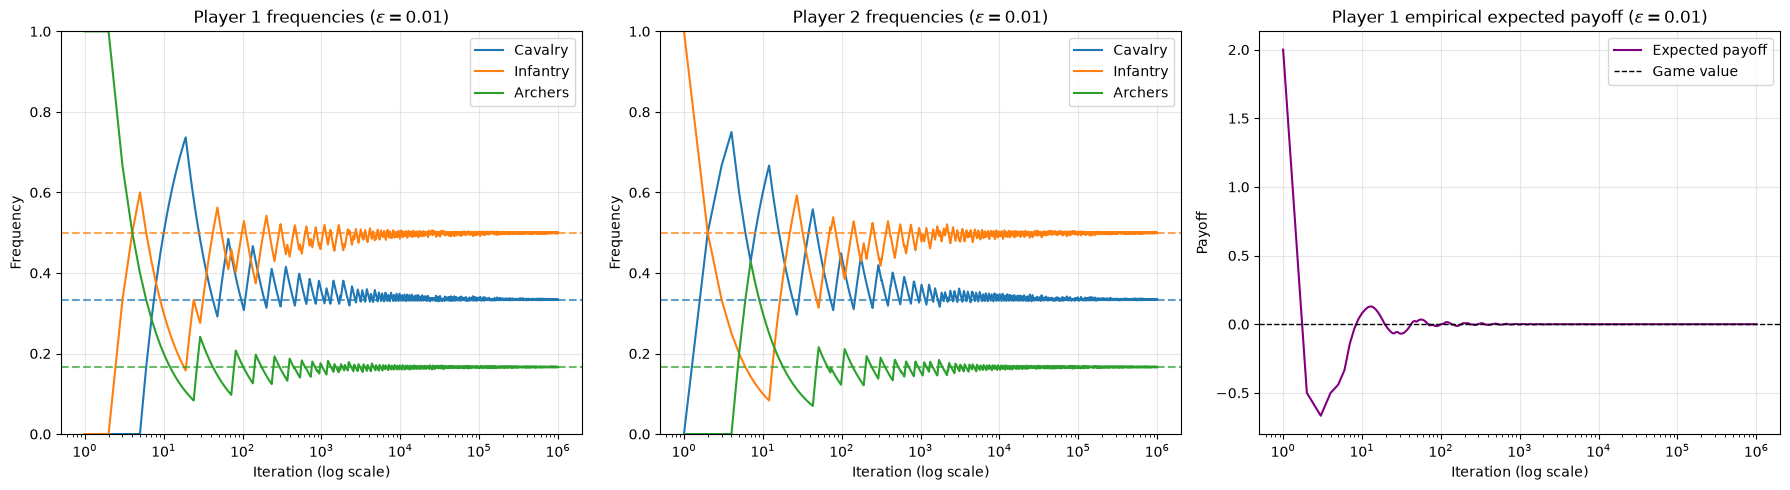

epsilon=0.01: final P1 frequencies=[0.333296 0.500256 0.166448]
epsilon=0.01: final P2 frequencies=[0.334838 0.498944 0.166218]
epsilon=0.01: final empirical expected payoff=0.000002


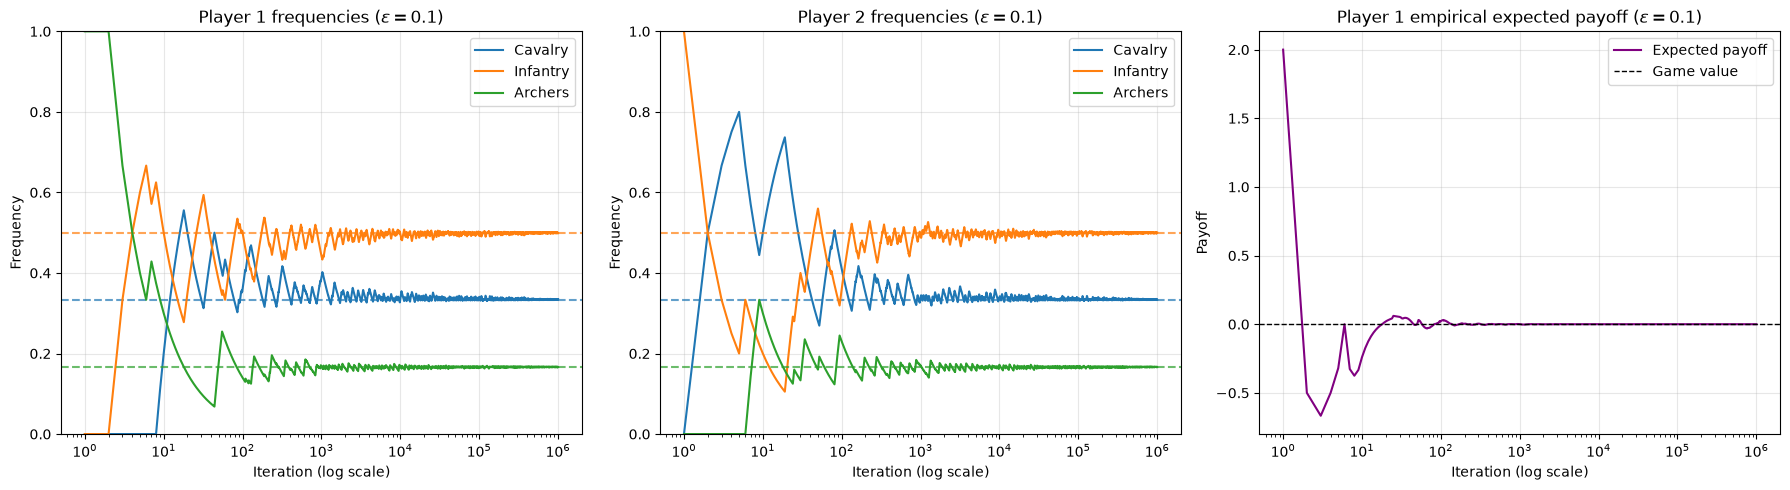

epsilon=0.1: final P1 frequencies=[0.335095 0.498573 0.166332]
epsilon=0.1: final P2 frequencies=[0.33348  0.500102 0.166418]
epsilon=0.1: final empirical expected payoff=-0.000002


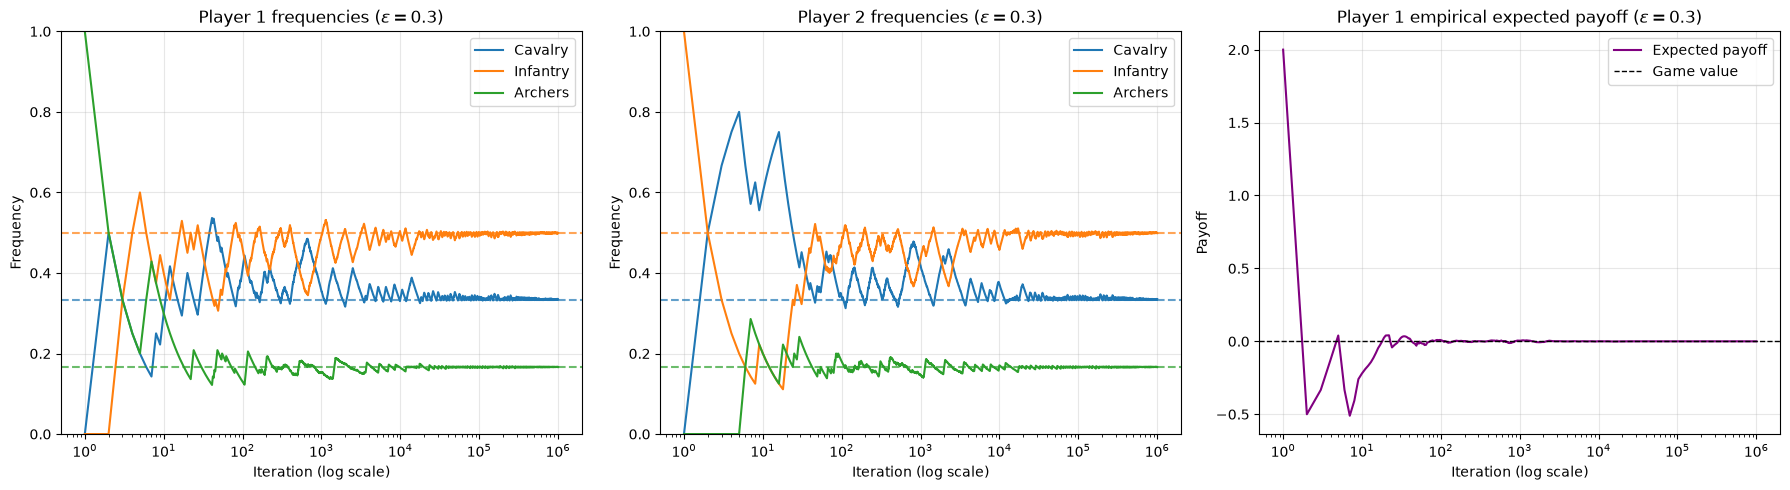

epsilon=0.3: final P1 frequencies=[0.334462 0.498987 0.166551]
epsilon=0.3: final P2 frequencies=[0.335024 0.498531 0.166445]
epsilon=0.3: final empirical expected payoff=-0.000000


In [2]:
import numpy as np
import matplotlib.pyplot as plt


def simulate_epsilon_greedy_fp(A, B, iterations, epsilon, seed=0):
    """Simulate simultaneous epsilon-greedy fictitious play."""
    A = np.asarray(A, dtype=np.float64)
    B = np.asarray(B, dtype=np.float64)
    if A.shape != B.shape or A.ndim != 2:
        raise ValueError("A and B must be two-dimensional matrices of equal shape")
    if iterations < 1:
        raise ValueError("iterations must be positive")
    if not 0.0 <= epsilon <= 1.0:
        raise ValueError("epsilon must be in [0, 1]")

    num_actions_p1, num_actions_p2 = A.shape
    rng = np.random.default_rng(seed)
    p1_counts = np.zeros(num_actions_p1, dtype=np.int64)
    p2_counts = np.zeros(num_actions_p2, dtype=np.int64)
    p1_freq_history = np.empty((iterations, num_actions_p1), dtype=np.float32)
    p2_freq_history = np.empty((iterations, num_actions_p2), dtype=np.float32)
    p1_expected_payoff_history = np.empty(iterations, dtype=np.float64)

    p1_action = int(rng.integers(num_actions_p1))
    p2_action = int(rng.integers(num_actions_p2))

    for t in range(iterations):
        p1_counts[p1_action] += 1
        p2_counts[p2_action] += 1
        p1_freq = p1_counts / (t + 1)
        p2_freq = p2_counts / (t + 1)

        p1_freq_history[t] = p1_freq
        p2_freq_history[t] = p2_freq
        p1_expected_payoff_history[t] = p1_freq @ A @ p2_freq

        p1_action_payoffs = A @ p2_freq
        p2_action_payoffs = p1_freq @ B

        if rng.random() < epsilon:
            p1_action = int(rng.integers(num_actions_p1))
        else:
            p1_action = random_argmax(p1_action_payoffs, rng)

        if rng.random() < epsilon:
            p2_action = int(rng.integers(num_actions_p2))
        else:
            p2_action = random_argmax(p2_action_payoffs, rng)

    return p1_freq_history, p2_freq_history, p1_expected_payoff_history


# Repeated here so this section can also be run independently after the helper
# random_argmax from Problem 2 has been defined.
A_mod = np.array([[0, -1, 3], [1, 0, -2], [-3, 2, 0]], dtype=np.float64)
B_mod = -A_mod
nash_mod = np.array([1 / 3, 1 / 2, 1 / 6])

iterations = 1_000_000
epss = [0.01, 0.1, 0.3]
epsilon_final_results = {}

for epsilon in epss:
    p1_freq_history, p2_freq_history, p1_payoff_history = simulate_epsilon_greedy_fp(
        A_mod, B_mod, iterations, epsilon, seed=0
    )
    epsilon_final_results[epsilon] = {
        "p1": p1_freq_history[-1].copy(),
        "p2": p2_freq_history[-1].copy(),
        "payoff": float(p1_payoff_history[-1]),
    }

    idx = np.unique(np.r_[0, np.geomspace(1, iterations - 1, 5000).astype(int)])
    x = idx + 1
    labels = ["Cavalry", "Infantry", "Archers"]
    colors = ["tab:blue", "tab:orange", "tab:green"]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for history, ax, player in [
        (p1_freq_history, axes[0], "Player 1"),
        (p2_freq_history, axes[1], "Player 2"),
    ]:
        for action, (label, color) in enumerate(zip(labels, colors)):
            ax.semilogx(x, history[idx, action], label=label, color=color)
            ax.axhline(nash_mod[action], color=color, linestyle="--", alpha=0.7)
        ax.set_title(f"{player} frequencies ($\\epsilon={epsilon}$)")
        ax.set_xlabel("Iteration (log scale)")
        ax.set_ylabel("Frequency")
        ax.set_ylim(0, 1)
        ax.legend()
        ax.grid(alpha=0.3)

    axes[2].semilogx(x, p1_payoff_history[idx], color="purple", label="Expected payoff")
    axes[2].axhline(0, color="black", linestyle="--", linewidth=1, label="Game value")
    axes[2].set_title(f"Player 1 empirical expected payoff ($\\epsilon={epsilon}$)")
    axes[2].set_xlabel("Iteration (log scale)")
    axes[2].set_ylabel("Payoff")
    axes[2].legend()
    axes[2].grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

    print(f"epsilon={epsilon}: final P1 frequencies={p1_freq_history[-1]}")
    print(f"epsilon={epsilon}: final P2 frequencies={p2_freq_history[-1]}")
    print(f"epsilon={epsilon}: final empirical expected payoff={p1_payoff_history[-1]:.6f}")

### Analysis of $\epsilon$-greedy Fictitious Play

With $\epsilon=0.01$, exploitation dominates and the trajectory closely resembles ordinary fictitious play. Larger $\epsilon$ produces noisier best-response dynamics and guarantees persistent coverage of every action, but it does **not** necessarily pull the final empirical frequencies monotonically toward the uniform distribution. The exploitative actions can change their long-run proportions and compensate for the uniform exploration component.

For these three tested values, the empirical frequencies can still approach the modified-game Nash distribution $(1/3,1/2,1/6)$ and the empirical expected payoff remains near the zero game value. A useful feasibility check is that $\epsilon$-greedy exploration alone gives every action a probability floor of $\epsilon/3$. Exact convergence to this NE becomes impossible once that floor exceeds its smallest component, $1/6$—that is, for $\epsilon>0.5$—and the process must then approach an $\epsilon$-perturbed regime instead. Thus increasing $\epsilon$ mainly increases persistent randomness and can slow convergence in the requested range; it does not automatically create a simple convex mixture of the NE and the uniform strategy.

### Algorithm

Regret Matching proceeds in three main steps.

#### 1. Regret Update

Suppose Player $i$ played action $a_i$ while the opponent played action $a_{-i}$. For every possible action $s \in A_i$, update the cumulative regret as

$$
R_t(s) = R_{t-1}(s) + u_i(s, a_{-i}) - u_i(a_i, a_{-i}).
$$

where

- $R_t(s)$ is the cumulative regret for not choosing action $s$.
- $u_i(s, a_{-i})$ is the payoff that would have been received by playing $s$.
- $u_i(a_i, a_{-i})$ is the payoff actually received.

#### 2. Strategy Update

Let the positive regret be

$$
R_t^{+}(s) = \max(0, R_t(s)).
$$

The probability of selecting action $s$ in the next round is

$$
p_{t+1}(s)
=
\frac{R_t^{+}(s)}
{\sum_{s' \in A_i} R_t^{+}(s')}.
$$

If

$$
\sum_{s' \in A_i} R_t^{+}(s') = 0,
$$

then choose uniformly at random among all actions.

#### 3. Total Regret Tracking

To verify that the algorithm is working correctly, also track the **sum of Player 1's positive cumulative regrets** after each iteration.

For a no-regret algorithm, the average regret should approach zero as the number of iterations increases.

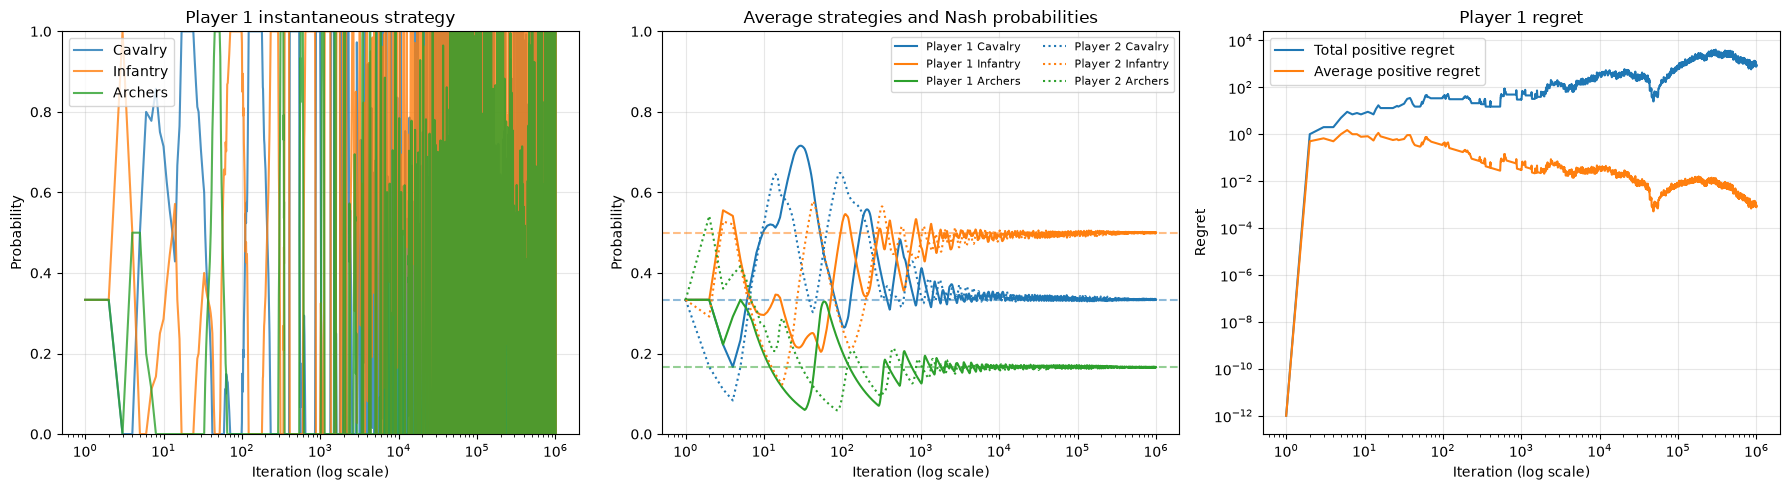

Final P1 average strategy: [0.33355385 0.50053805 0.1659081 ]
Final P2 average strategy: [0.3328517  0.49977693 0.16737136]
Modified-game Nash strategy: [0.33333333 0.5        0.16666667]
Final P1 total positive regret: 847.000
Final P1 average positive regret: 0.000847


In [3]:
import numpy as np
import matplotlib.pyplot as plt


def strategy_from_regrets(regrets):
    """Regret-matching distribution formed from positive cumulative regrets."""
    positive = np.maximum(regrets, 0.0)
    total = positive.sum()
    if total <= 0.0:
        return np.full(regrets.size, 1.0 / regrets.size)
    return positive / total


def simulate_regret_matching(A, B, iterations, seed=0):
    """Simulate two-player regret matching and return strategy histories."""
    A = np.asarray(A, dtype=np.float64)
    B = np.asarray(B, dtype=np.float64)
    if A.shape != B.shape or A.ndim != 2:
        raise ValueError("A and B must be two-dimensional matrices of equal shape")
    if iterations < 1:
        raise ValueError("iterations must be positive")

    num_actions_p1, num_actions_p2 = A.shape
    rng = np.random.default_rng(seed)
    p1_inst_strat_hist = np.empty((iterations, num_actions_p1), dtype=np.float32)
    p1_avg_strat_hist = np.empty((iterations, num_actions_p1), dtype=np.float32)
    p2_inst_strat_hist = np.empty((iterations, num_actions_p2), dtype=np.float32)
    p2_avg_strat_hist = np.empty((iterations, num_actions_p2), dtype=np.float32)
    p1_total_regret_hist = np.empty(iterations, dtype=np.float64)

    p1_regrets = np.zeros(num_actions_p1)
    p2_regrets = np.zeros(num_actions_p2)
    p1_strat_sum = np.zeros(num_actions_p1)
    p2_strat_sum = np.zeros(num_actions_p2)

    for t in range(iterations):
        p1_strategy = strategy_from_regrets(p1_regrets)
        p2_strategy = strategy_from_regrets(p2_regrets)
        p1_inst_strat_hist[t] = p1_strategy
        p2_inst_strat_hist[t] = p2_strategy

        p1_action = int(rng.choice(num_actions_p1, p=p1_strategy))
        p2_action = int(rng.choice(num_actions_p2, p=p2_strategy))

        p1_actual_payoff = A[p1_action, p2_action]
        p2_actual_payoff = B[p1_action, p2_action]
        p1_regrets += A[:, p2_action] - p1_actual_payoff
        p2_regrets += B[p1_action, :] - p2_actual_payoff

        p1_strat_sum += p1_strategy
        p2_strat_sum += p2_strategy
        p1_avg_strat_hist[t] = p1_strat_sum / (t + 1)
        p2_avg_strat_hist[t] = p2_strat_sum / (t + 1)
        p1_total_regret_hist[t] = np.maximum(p1_regrets, 0.0).sum()

    return (
        p1_avg_strat_hist,
        p1_inst_strat_hist,
        p2_avg_strat_hist,
        p2_inst_strat_hist,
        p1_total_regret_hist,
    )


iterations = 1_000_000
(
    p1_avg_strat_hist,
    p1_inst_strat_hist,
    p2_avg_strat_hist,
    p2_inst_strat_hist,
    p1_total_regret_hist,
) = simulate_regret_matching(A_mod, B_mod, iterations, seed=0)

idx = np.unique(np.r_[0, np.geomspace(1, iterations - 1, 5000).astype(int)])
x = idx + 1
labels = ["Cavalry", "Infantry", "Archers"]
colors = ["tab:blue", "tab:orange", "tab:green"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for action, (label, color) in enumerate(zip(labels, colors)):
    axes[0].semilogx(x, p1_inst_strat_hist[idx, action], color=color, alpha=0.8, label=label)
axes[0].set_title("Player 1 instantaneous strategy")
axes[0].set_xlabel("Iteration (log scale)")
axes[0].set_ylabel("Probability")
axes[0].set_ylim(0, 1)
axes[0].legend()
axes[0].grid(alpha=0.3)

for history, linestyle, player in [
    (p1_avg_strat_hist, "-", "Player 1"),
    (p2_avg_strat_hist, ":", "Player 2"),
]:
    for action, (label, color) in enumerate(zip(labels, colors)):
        axes[1].semilogx(
            x, history[idx, action], color=color, linestyle=linestyle,
            label=f"{player} {label}",
        )
        if player == "Player 1":
            axes[1].axhline(nash_mod[action], color=color, linestyle="--", alpha=0.5)
axes[1].set_title("Average strategies and Nash probabilities")
axes[1].set_xlabel("Iteration (log scale)")
axes[1].set_ylabel("Probability")
axes[1].set_ylim(0, 1)
axes[1].legend(ncol=2, fontsize=8)
axes[1].grid(alpha=0.3)

axes[2].loglog(x, np.maximum(p1_total_regret_hist[idx], 1e-12), label="Total positive regret")
axes[2].loglog(
    x,
    np.maximum(p1_total_regret_hist[idx] / x, 1e-12),
    label="Average positive regret",
)
axes[2].set_title("Player 1 regret")
axes[2].set_xlabel("Iteration (log scale)")
axes[2].set_ylabel("Regret")
axes[2].legend()
axes[2].grid(alpha=0.3)

fig.tight_layout()
plt.show()

print(f"Final P1 average strategy: {p1_avg_strat_hist[-1]}")
print(f"Final P2 average strategy: {p2_avg_strat_hist[-1]}")
print(f"Modified-game Nash strategy: {nash_mod}")
print(f"Final P1 total positive regret: {p1_total_regret_hist[-1]:.3f}")
print(f"Final P1 average positive regret: {p1_total_regret_hist[-1] / iterations:.6f}")

### Analysis of Regret Matching

The instantaneous regret-matching strategy need not settle; it may continue to move sharply as the signs and magnitudes of cumulative regrets change. The relevant no-regret result concerns the **time-average strategy**. In this two-player zero-sum game, the average strategies should approach the minimax/Nash distribution $(1/3,1/2,1/6)$ even while the instantaneous strategies fluctuate.

The total positive cumulative regret is not required to decrease and can grow sublinearly. The diagnostic that should approach zero is its normalized value, `total_positive_regret / t`. Thus a growing total-regret curve is not by itself a failure if the average-regret curve trends downward toward zero.